# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди - аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки -
номер варіанта, ринок і товар визначаться автоматично.

In [36]:
SURNAME_NAME = 'Гнатюк Ярослав'
GROUP        = 'ШІ-31'
NUMBER       = 4

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Гнатюк Ярослав | ШІ-31 | номер 4


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD -')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 4   ·   Гнатюк Ярослав   ·   ШІ-31

   Ринок:  Kherson
   Товар:  сметана   (у наборі даних: Sour cream - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD -
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** - у Python та в Orange -
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** -
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** - цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** - експортований ряд (завдання 9).
3. **`потік_orange.ows`** - збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 - вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** - у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта - скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, - і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник - і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного - перевірте, чи правильно побудована сітка.

In [3]:
import pandas as pd

In [4]:
df = pd.read_csv(r"D:\Projects\PycharmProjects\DA_Labs\lab4\ціни_україна_2014_2017.csv")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29091 entries, 0 to 29090
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   ринок    29091 non-null  object 
 1   товар    29091 non-null  object 
 2   одиниця  29091 non-null  object 
 3   валюта   29091 non-null  object 
 4   рік      29091 non-null  int64  
 5   місяць   29091 non-null  int64  
 6   ціна     29091 non-null  float64
dtypes: float64(1), int64(2), object(4)
memory usage: 1.6+ MB


In [6]:
DF = df[(df["ринок"] == MARKET) & (df["товар"] == GOOD)]

In [7]:
START = '2014-03-01'
END = '2017-12-01'

DF = DF.assign(дата=pd.to_datetime({'year': DF['рік'], 'month': DF['місяць'], 'day': 1}))
grid = pd.date_range(START, END, freq='MS')
series = DF.set_index('дата')['ціна'].reindex(grid)
series.index.name = 'дата'

print('Місяців у сітці:', len(grid))
print('Місяців з виміром:', series.notna().sum())
print('Пропуски:', series[series.isna()].index.strftime('%Y-%m').tolist())

Місяців у сітці: 46
Місяців з виміром: 45
Пропуски: ['2017-08']


In [8]:
coverage = df[(df['рік'] == 2017) & (df['місяць'].between(7, 9))]
print(coverage.groupby('місяць').size())

місяць
7    650
9    650
dtype: int64


**Висновок до завдання 1:**

Всього проміжок охоплює 46 місяців, проте місяців із виміром є тільки 45. У сітці немає серпня 2017 року, перевірка показала, що записів за цей місяць немає по всьому датасету, а не тільки у нашій вибірці, що свідчить, що помилка лежить на рівні джерела: у цьому місяці збір цін не проводили, або дані не опублікували, або їх не додали в набір

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** - наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [9]:
regions = pd.DataFrame(df.groupby('ринок')['рік'].max())
regions[regions["рік"] < 2017]

,рік
ринок,
Crimea,2014
m. Sevastopol,2014


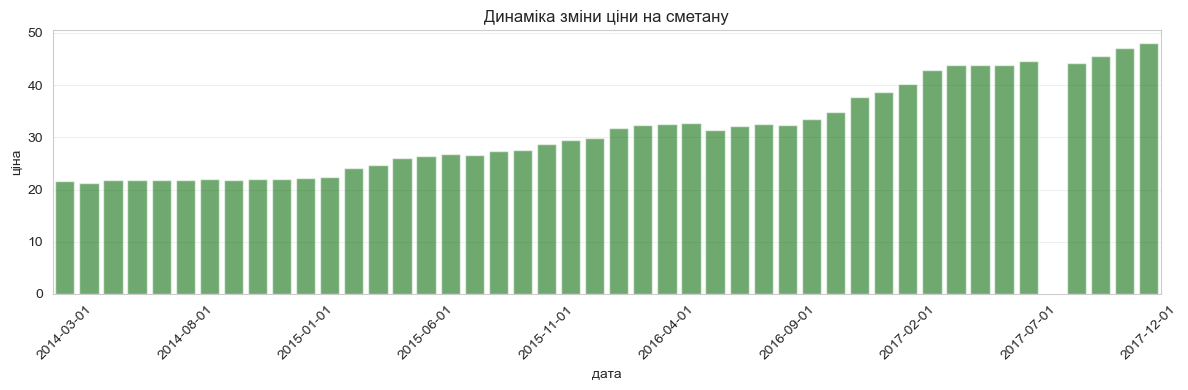

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

series_df = pd.DataFrame(series)

sns.set_style('whitegrid')
plt.figure(figsize=(12, 4))
plt.title("Динаміка зміни ціни на сметану")

ax = sns.barplot(data=series_df, x="дата", y="ціна", color="green", alpha=0.6)

ax.set_xticks(ax.get_xticks()[::5])
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [11]:
GAP_DATE = series.index[series.isna()][0]

filled_ffill = series.ffill()
filled_linear = series.interpolate(method='linear')
filled_polynomial = pd.Series(series.reset_index(drop=True).interpolate(method='polynomial', order=3).to_numpy(), index=series.index)

gap_values = pd.DataFrame({
    'перенесення останнього': filled_ffill,
    'лінійна інтерполяція': filled_linear,
    'поліномальна інтерполяція': filled_polynomial,
}).loc[[GAP_DATE]]

print('Сусідні значення:', series.loc[GAP_DATE - pd.offsets.MonthBegin(1)], series.loc[GAP_DATE + pd.offsets.MonthBegin(1)])
print(gap_values.round(4).T)

SERIES = filled_polynomial

Сусідні значення: 44.54 44.2067
дата                       2017-08-01
перенесення останнього        44.5400
лінійна інтерполяція          44.3734
поліномальна інтерполяція     44.2348


**Висновок до завдання 2:**

Для подальшої роботи обрав поліноміальну інтерполяцію. Вона будується за всіма спостереженнями ряду, а не лише за двома сусідніми, тому враховує загальну форму динаміки, а не припускає ні сталість ціни, ні строго рівномірну зміну між двома точками. Графік показує плавне зростання без різких стрибків і коливань, тому гладка крива є правдоподібною

Заповнення пропуску припустиме лише тоді, коли спостереження існувало, але не потрапило в дані. Воно неприпустиме, коли ряд обірвався назавжди. У цьому наборі так сталося з Кримом та Севастополем, які зникають із моніторингу у 2014 році. Для них немає "пропущеного місяця", ринку в моніторингу більше немає, тож інтерполяція створила б вигадані ціни на неіснуючому для спостереження ринку

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка - яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія - це твердження про дані.

In [12]:
import matplotlib.pyplot as plt

FIGSIZE = (11, 4)
BAR_WIDTH = 20

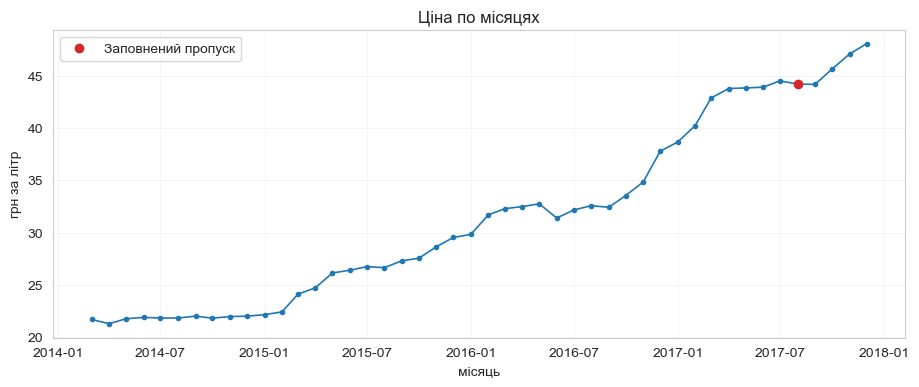

In [13]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(SERIES.index, SERIES.values, marker='o', markersize=3, linewidth=1.2, color='tab:blue')
ax.scatter([GAP_DATE], [SERIES.loc[GAP_DATE]], color='tab:red', zorder=3, label='Заповнений пропуск')
ax.set_title(f'Ціна по місяцях')
ax.set_xlabel('місяць')
ax.set_ylabel('грн за літр')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

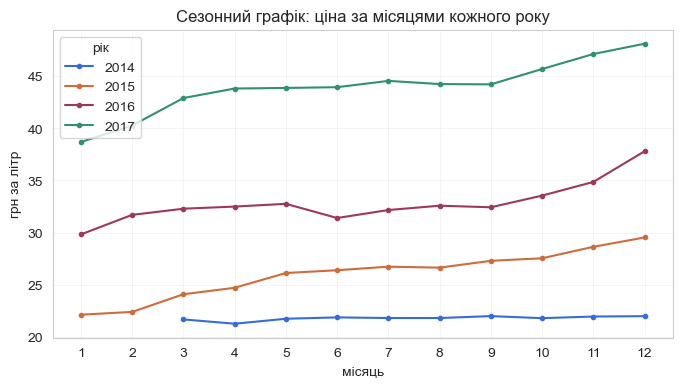

In [14]:
seasonal_table = (SERIES.to_frame('price')
                  .assign(year=SERIES.index.year, month=SERIES.index.month)
                  .pivot(index='month', columns='year', values='price'))

fig, ax = plt.subplots(figsize=(8, 4))
for year in seasonal_table.columns:
    ax.plot(seasonal_table.index, seasonal_table[year], marker='o', markersize=3, label=year)
ax.set_title('Сезонний графік: ціна за місяцями кожного року')
ax.set_xlabel('місяць')
ax.set_ylabel('грн за літр')
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)
ax.legend(title='рік')
plt.show()

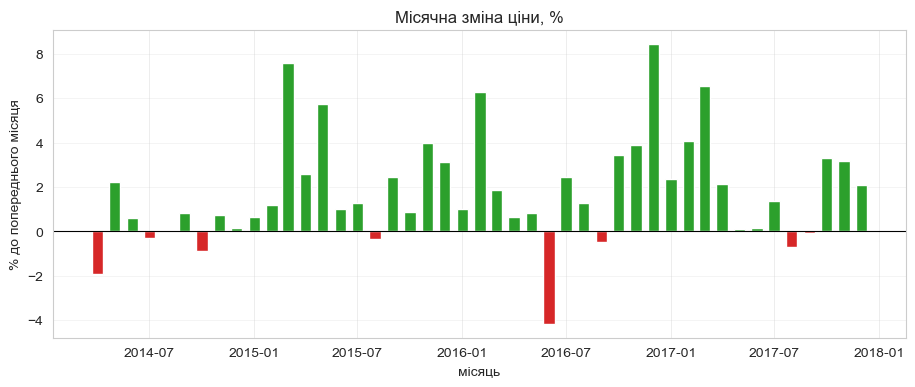

In [15]:
pct_change = SERIES.pct_change().dropna() * 100

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.bar(pct_change.index, pct_change.values, width=BAR_WIDTH,
       color=['tab:green' if v >= 0 else 'tab:red' for v in pct_change.values])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Місячна зміна ціни, %')
ax.set_xlabel('місяць')
ax.set_ylabel('% до попереднього місяця')
ax.grid(alpha=0.3, axis='y')
plt.show()

**Висновок до завдання 3:**

1. Геометрію лінії обрано тому, що вона найкраще підходить для відображення безперервних змін показника в часі (трендів), а абсолютна шкала дозволяє оцінити загальне зростання ціни на товар протягом усього періоду

2. Обрано геометрію накладених ліній для кожного окремого року на одній місячній шкалі. Це дозволяє візуально порівняти поведінку ціни всередині року та виявити, чи повторюються певні патерни з року в рік

3. Використано стовпці із розбиттям відносно нульової осі. Геометрія стовпців та відсоткова шкала ідеально підходять для візуалізації волатильності: кольорове кодування (зелений/червоний) миттєво показує напрямок зміни, а висота стовпця її амплітуду

Судячи з сезонного графіка, незважаючи на те, що сметана є молочним продуктом (для яких часто характерна сезонність через зміну надоїв влітку та взимку), чіткий повторюваний річний патерн відсутній. Криві різних років поводяться по-різному (наприклад, різкий стрибок у другій половині 2017 року не має аналогів у попередніх роках)

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання - вирішити, чи вона означає щось, а не чи вона є.

In [16]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

PERIOD = 12
STRENGTH_THRESHOLD = 0.64
FIGSIZE = (11, 9)

In [17]:
stl = STL(SERIES, period=PERIOD, robust=True).fit()
trend, seasonal, resid = stl.trend, stl.seasonal, stl.resid

F_S = max(0.0, 1 - resid.var() / (seasonal + resid).var())
F_T = max(0.0, 1 - resid.var() / (trend + resid).var())

print(f'F_S = {F_S:.3f}')
print(f'F_T = {F_T:.3f}')
print(f'Поріг сили = {STRENGTH_THRESHOLD}; сезонність сильна: {F_S > STRENGTH_THRESHOLD}')

F_S = 0.549
F_T = 0.990
Поріг сили = 0.64; сезонність сильна: False


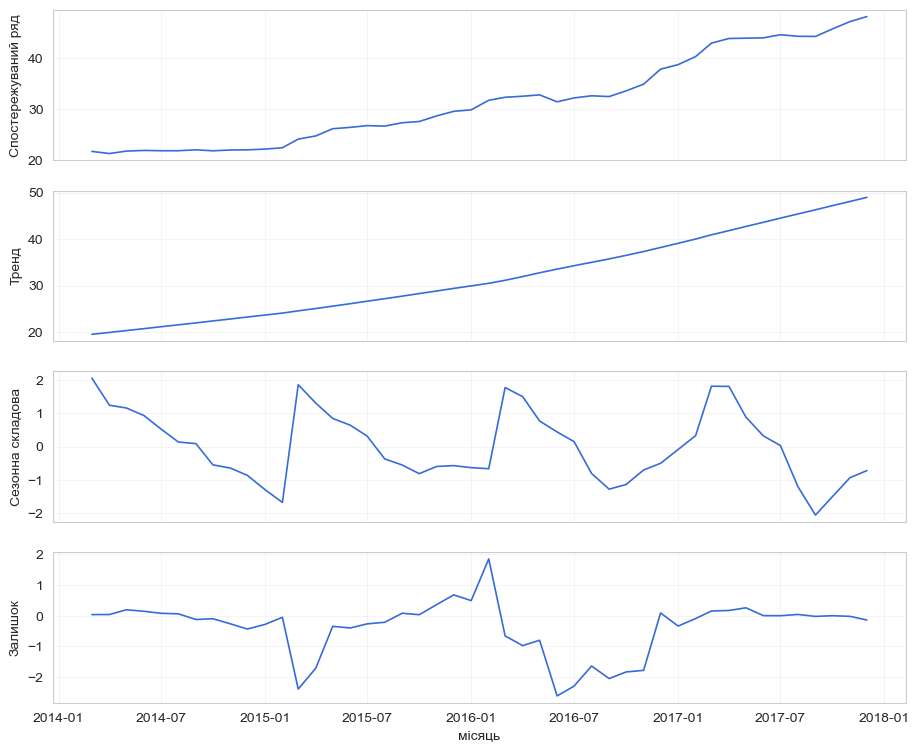

In [18]:
fig, axes = plt.subplots(4, 1, figsize=FIGSIZE, sharex=True)
panels = [('Спостережуваний ряд', SERIES), ('Тренд', trend), ('Сезонна складова', seasonal), ('Залишок', resid)]
for ax, (title, component) in zip(axes, panels):
    ax.plot(component.index, component.values, linewidth=1.2)
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('місяць')
plt.show()

**Висновок до завдання 4:**

За результатами розкладання часового ряду отримано такі показники:
- Сила тренду (F_T) дорівнює 0.990, що свідчить про дуже потужний і стабільний висхідний тренд (ціна впевнено зростає протягом усього періоду)
- Сила сезонності (F_S) дорівнює 0.549
-
Сезонна складова STL має пилкоподібну форму: щороку різкий підйом у лютому–березні (до ≈ 1.8–2.0 грн) і повільне спадання до осені (до ≈ −1.3…−2.1 грн). Розмах ≈ 3.5–4 грн становить 8–15 % рівня ціни, що значно менше за зміну тренду (з ≈ 22 до ≈ 48 грн). Форма сезонності змінюється рік у рік, а в залишку лишаються великі провали (2015, 2016) і пік 2016 року, тобто залишок не схожий на білий шум. За ряду з лише 3–4 повними циклами не можна відрізнити справжню сезонність від повторюваних весняних стрибків цін, зумовлених інфляцією. Це узгоджується з F_S = 0.549 < 0.64: сезонність слабка.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються - ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

In [19]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import matplotlib.pyplot as plt

NLAGS = 20
FIGSIZE = (12, 8)

DIFF = SERIES.diff().dropna()

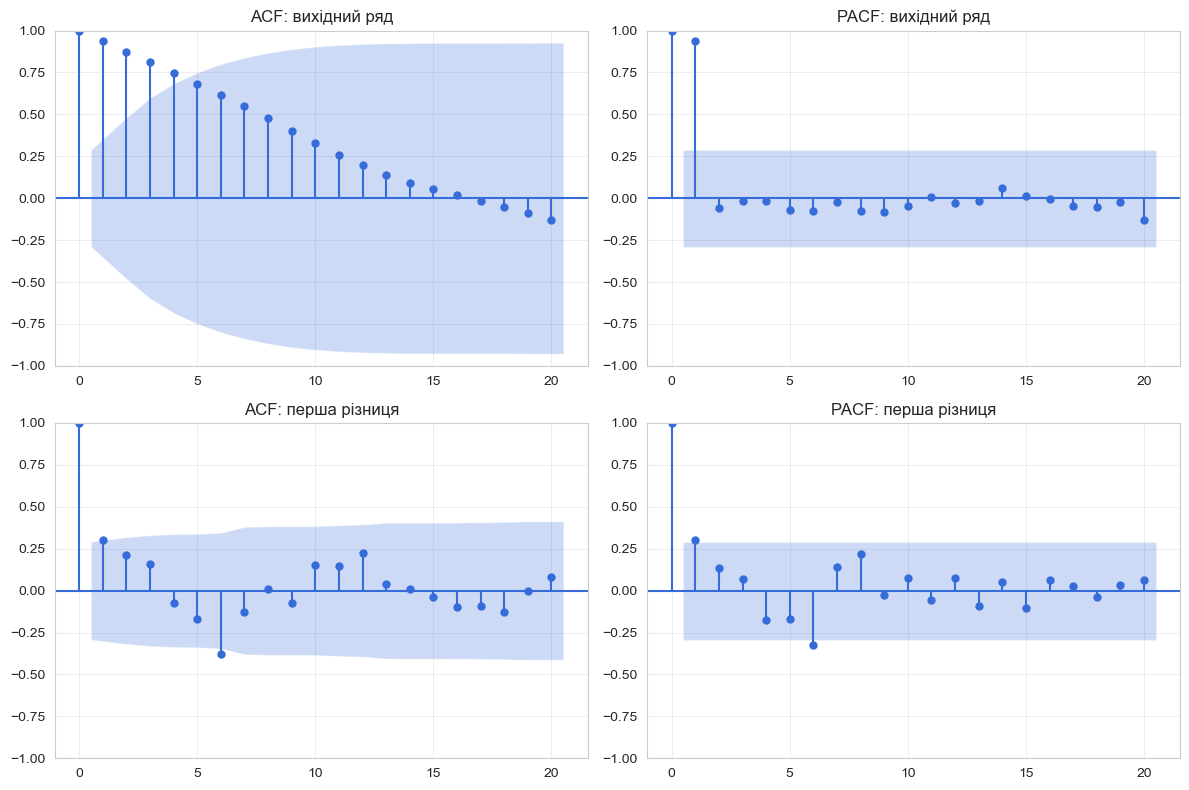

In [20]:
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE)
plot_acf(SERIES, lags=NLAGS, ax=axes[0, 0], title='ACF: вихідний ряд')
plot_pacf(SERIES, lags=NLAGS, method='ywm', ax=axes[0, 1], title='PACF: вихідний ряд')
plot_acf(DIFF, lags=NLAGS, ax=axes[1, 0], title='ACF: перша різниця')
plot_pacf(DIFF, lags=NLAGS, method='ywm', ax=axes[1, 1], title='PACF: перша різниця')
plt.tight_layout()
plt.show()

In [21]:
rows = []
for name, s in {'вихідний ряд': SERIES, 'перша різниця': DIFF}.items():
    rows.append({
        'ряд': name,
        'ADF p-значення': adfuller(s, autolag='AIC')[1],
        'KPSS p-значення': kpss(s, regression='c', nlags='auto')[1],
    })

stationarity = pd.DataFrame(rows).set_index('ряд')
print(stationarity.round(4))

               ADF p-значення  KPSS p-значення
ряд                                           
вихідний ряд           0.9991             0.01
перша різниця          0.0016             0.10


C:\Users\Yaroslav\AppData\Local\Temp\ipykernel_6420\164924574.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF p-значення': adfuller(s, autolag='AIC')[1],
C:\Users\Yaroslav\AppData\Local\Temp\ipykernel_6420\164924574.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  'KPSS p-значення': kpss(s, regression='c', nlags='auto')[1],
C:\Users\Yaroslav\AppData\Local\Temp\ipykernel_6420\164924574.py:6: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In

**Висновок до завдання 5:**

- Вихідний ряд є нестаціонарним: Тест ADF не відхиляє наявність одиничного кореня, а тест KPSS відхиляє стаціонарність. Обидва тести одностайно підтверджують наявність тренду, що ідеально збігається з повільним спаданням стовпців на початковому графіку ACF
- Перша різниця є стаціонарною: Після диференціювання ситуація дзеркально змінюється. ADF підтверджує відсутність одиничного кореня, а KPSS підтверджує стаціонарність ряду. Це доводить, що взяття різниці першого порядку успішно видалило тренд (що також було видно по різкому затуханню на нижніх графіках ACF/PACF)

Загальний підсумок для моделювання:
Часовий ряд вимагає інтегрування (диференціювання) першого порядку, тобто параметр d = 1. Спираючись на значущі перші лаги на графіках ACF та PACF для першої різниці, оптимальною базовою моделлю для подальшого прогнозування буде ARIMA(1, 1, 1)

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** - поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко - у Частині 2 вона має збігтися з налаштуваннями Orange.

In [22]:
import numpy as np

N_FOLDS = 7
STEPS = 3
SEASON = 12
TEST_SIZE = 0.25
RANDOM_STATE = 42

values = SERIES.to_numpy()
n_obs = len(values)
first_test = n_obs - N_FOLDS * STEPS
folds = [(first_test + i * STEPS, first_test + (i + 1) * STEPS) for i in range(N_FOLDS)]


def naive(train, h):
    return np.full(h, train[-1])


def seasonal_naive(train, h):
    return train[-SEASON:][:h]


def mean_forecast(train, h):
    return np.full(h, train.mean())


def drift(train, h):
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return train[-1] + slope * np.arange(1, h + 1)


FORECASTERS = {
    'наївний': naive,
    'сезонний наївний': seasonal_naive,
    'середнє': mean_forecast,
    'дрейф': drift,
}

In [23]:
def metrics(actual, predicted):
    error = actual - predicted
    return {
        'MAE': np.mean(np.abs(error)),
        'RMSE': np.sqrt(np.mean(error ** 2)),
        'MAPE, %': np.mean(np.abs(error / actual)) * 100,
    }


def rolling_origin(forecaster):
    actual = np.concatenate([values[start:end] for start, end in folds])
    predicted = np.concatenate([forecaster(values[:start], end - start) for start, end in folds])
    return actual, predicted


baseline_table = pd.DataFrame({name: metrics(*rolling_origin(f)) for name, f in FORECASTERS.items()}).T

print('Фолди (довжина навчання, тест від-до):', [(start, start, end) for start, end in folds])
print(baseline_table.round(3))
print('Найкращий за MAE:', baseline_table['MAE'].idxmin())

Фолди (довжина навчання, тест від-до): [(25, 25, 28), (28, 28, 31), (31, 31, 34), (34, 34, 37), (37, 37, 40), (40, 40, 43), (43, 43, 46)]
                     MAE    RMSE  MAPE, %
наївний            1.632   2.206    4.081
сезонний наївний   9.047   9.436   22.491
середнє           11.914  12.563   29.380
дрейф              1.177   1.634    2.975
Найкращий за MAE: дрейф


In [24]:
rng = np.random.default_rng(RANDOM_STATE)
n_test = int(round(n_obs * TEST_SIZE))
test_idx = np.sort(rng.choice(np.arange(SEASON, n_obs), size=n_test, replace=False))
train_idx = np.setdiff1d(np.arange(n_obs), test_idx)


def last_train_at_or_before(position):
    return train_idx[train_idx <= position].max()


def random_split_forecast(name, t):
    if name == 'наївний':
        return values[last_train_at_or_before(t - 1)]
    if name == 'сезонний наївний':
        return values[last_train_at_or_before(t - SEASON)]
    if name == 'середнє':
        return values[train_idx].mean()
    ref = last_train_at_or_before(t - 1)
    slope = (values[ref] - values[train_idx[0]]) / (ref - train_idx[0])
    return values[ref] + slope * (t - ref)


random_table = pd.DataFrame({
    name: metrics(values[test_idx], np.array([random_split_forecast(name, t) for t in test_idx]))
    for name in FORECASTERS
}).T

print('Випадковий поділ 75/25:')
print(random_table.round(3))
print('Відношення (рухомий початок / випадковий поділ):')
print((baseline_table / random_table).round(2))

Випадковий поділ 75/25:
                    MAE   RMSE  MAPE, %
наївний           1.184  1.349    3.563
сезонний наївний  7.674  8.200   21.218
середнє           6.823  8.885   17.392
дрейф             0.767  0.975    2.315
Відношення (рухомий початок / випадковий поділ):
                   MAE  RMSE  MAPE, %
наївний           1.38  1.63     1.15
сезонний наївний  1.18  1.15     1.06
середнє           1.75  1.41     1.69
дрейф             1.54  1.68     1.29


**Висновок до завдання 6:**

Найкращий базис - дрейф (MAE = 1.177). Він ідеально відповідає природі ряду, оскільки лінійно продовжує сильний висхідний тренд за відсутності значущої сезонності

Випадковий поділ (75/25) є некоректним. Він занижує справжню похибку в 1.15–1.75 раза, оскільки перемішування даних дозволяє моделі "підглядати" в майбутнє

Рухомий початок (7 фолдів) - надійний метод оцінки. Він чесно імітує реальне прогнозування крок за кроком, даючи об'єктивну оцінку якості моделі без витоку даних (data leakage)

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** - саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** - і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису - це законний результат, а не помилка. Напишіть про це прямо.

In [25]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt

ORDER = (1, 1, 1)
LJUNG_BOX_LAGS = 10
ACF_LAGS = 20
FIGSIZE = (11, 6)

In [26]:
def arima_forecaster(train, h):
    return np.asarray(ARIMA(train, order=ORDER).fit().forecast(h))


arima_actual, arima_predicted = rolling_origin(arima_forecaster)
arima_metrics = metrics(arima_actual, arima_predicted)

comparison = pd.concat([baseline_table, pd.DataFrame({'ARIMA(1,1,1)': arima_metrics}).T])
best_baseline = baseline_table['MAE'].idxmin()

print(comparison.round(3))
print('Найкращий базис:', best_baseline)
print('ARIMA / найкращий базис:')
print((comparison.loc['ARIMA(1,1,1)'] / comparison.loc[best_baseline]).round(2))

                     MAE    RMSE  MAPE, %
наївний            1.632   2.206    4.081
сезонний наївний   9.047   9.436   22.491
середнє           11.914  12.563   29.380
дрейф              1.177   1.634    2.975
ARIMA(1,1,1)       1.709   2.163    4.401
Найкращий базис: дрейф
ARIMA / найкращий базис:
MAE        1.45
RMSE       1.32
MAPE, %    1.48
dtype: float64


D:\Programs\Anaconda3\envs\workspace\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


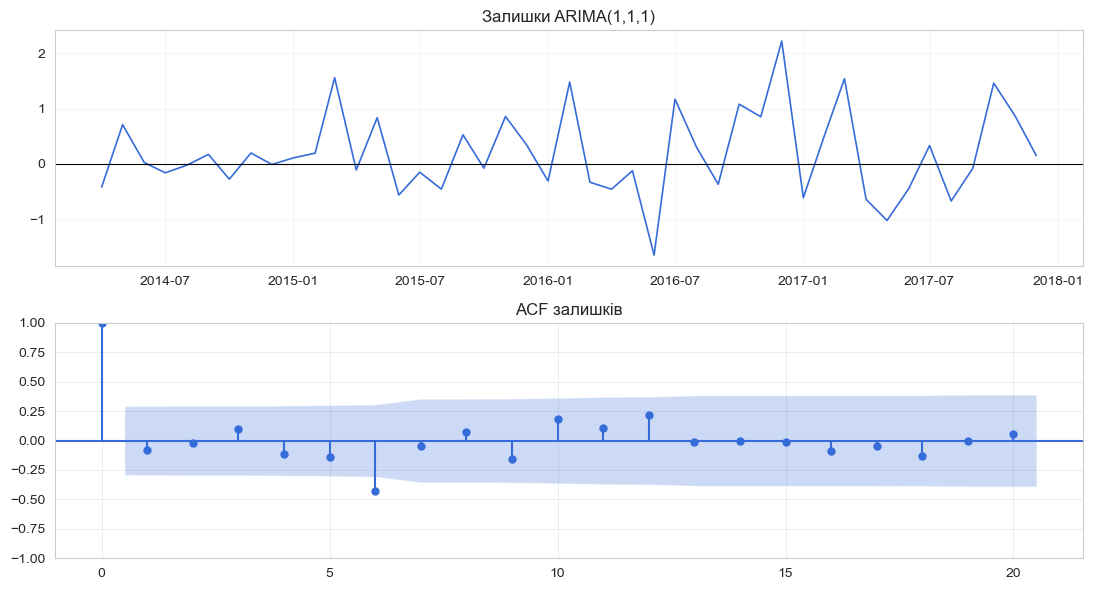

      lb_stat  lb_pvalue
10  16.551929   0.084885


In [27]:
fit_full = ARIMA(SERIES, order=ORDER).fit()
residuals = fit_full.resid.iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=FIGSIZE)
axes[0].plot(residuals.index, residuals.values, linewidth=1.2)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Залишки ARIMA(1,1,1)')
axes[0].grid(alpha=0.3)
plot_acf(residuals, lags=ACF_LAGS, ax=axes[1], title='ACF залишків')
plt.tight_layout()
plt.show()

print(acorr_ljungbox(residuals, lags=[LJUNG_BOX_LAGS]))

**Висновок до завдання 7:**

Оцінка та обґрунтування порядку: ARIMA(1,1,1) показала MAE = 1.709. Порядок (1,1,1) обрано коректно: перша різниця (d=1) успішно видалила тренд, а значущі перші лаги на графіках ACF та PACF диференційованого ряду вказують на необхідність параметрів p=1 та q=1

Порівняння з базисом: ARIMA програла базису "дрейф" (MAE 1.709 проти 1.177). Це закономірний результат: оскільки ряд має потужний лінійний висхідний тренд без сезонності, найпростіша екстраполяція прямою лінією (дрейф) працює краще. Використовувати складнішу ARIMA на цих даних недоцільно

Аналіз залишків: З математичної точки зору модель відпрацювала відмінно. Судячи з графіка ACF та тесту Льюнга-Бокса (p-value = 0.084 > 0.05), у залишках не лишилося жодної структури - вони є звичайним білим шумом. Модель витягнула з даних усю можливу інформацію

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** - і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці - це сезон.

In [28]:
from scipy import stats
import matplotlib.pyplot as plt

MIN_SEGMENT = 6
ALPHA = 0.05
FIGSIZE = (11, 4)

In [29]:
scan_rows = []
for k in range(MIN_SEGMENT, len(SERIES) - MIN_SEGMENT + 1):
    before, after = SERIES.iloc[:k], SERIES.iloc[k:]
    t_stat, p_value = stats.ttest_ind(after, before, equal_var=False)
    scan_rows.append({
        'date': SERIES.index[k],
        't': t_stat,
        'p': p_value,
        'mean_before': before.mean(),
        'mean_after': after.mean(),
    })

scan = pd.DataFrame(scan_rows).set_index('date')
change_date = scan['t'].abs().idxmax()
change = scan.loc[change_date]
p_adjusted = min(1.0, change['p'] * len(scan))

print('Кандидатних дат:', len(scan))
print('Дата зміни:', change_date.strftime('%Y-%m'))
print(f't = {change["t"]:.2f}')
print(f'середнє до = {change["mean_before"]:.2f}, після = {change["mean_after"]:.2f}')
print(f'p = {change["p"]:.4g}; з поправкою Бонферроні = {p_adjusted:.4g}; значущість при alpha {ALPHA}: {p_adjusted < ALPHA}')

Кандидатних дат: 35
Дата зміни: 2017-03
t = 16.04
середнє до = 27.85, після = 44.84
p = 6.265e-20; з поправкою Бонферроні = 2.193e-18; значущість при alpha 0.05: True


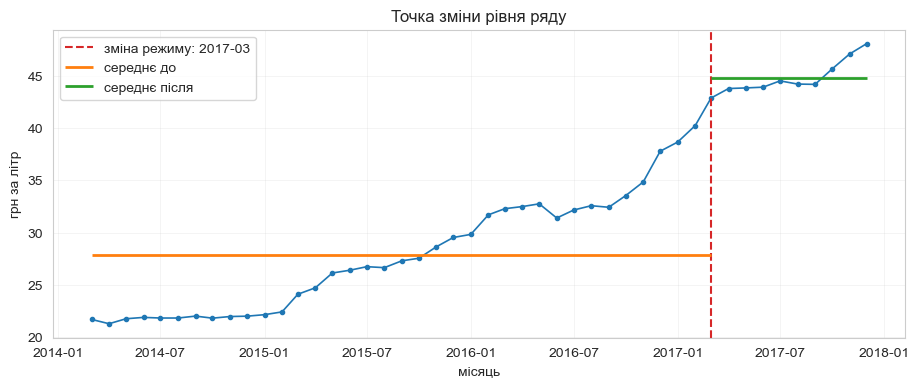

In [30]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(SERIES.index, SERIES.values, marker='o', markersize=3, linewidth=1.2, color='tab:blue')
ax.axvline(change_date, color='tab:red', linestyle='--', label=f'зміна режиму: {change_date:%Y-%m}')
ax.hlines(change['mean_before'], SERIES.index[0], change_date, color='tab:orange', linewidth=2, label='середнє до')
ax.hlines(change['mean_after'], change_date, SERIES.index[-1], color='tab:green', linewidth=2, label='середнє після')
ax.set_title('Точка зміни рівня ряду')
ax.set_xlabel('місяць')
ax.set_ylabel('грн за літр')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Висновок до завдання 8:**

Точкою зміну рівня ряду виявилося 2017-03, адже саме після неї середнє по всьому ряді зросла найбільше

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок - для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших - як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

### Перелік знайдених помилок

| №  | Клітинка (розділ) | Суть помилки | Чим небезпечна |
|----|---|---|---|
| 1  | 3 (1. Підготовка даних) | Сітка `grid` створена, але не використана. `s.isna()` перевіряє ряд без сітки, тож пропуск неможливо виявити. Насправді в ряді 45 із 46 місяців, немає серпня 2017. Висновок "пропусків немає" хибний | Усі подальші кроки (`shift(12)`, STL, ARIMA) припускають рівномірну місячну сітку. Після пропуску лаги зсуваються на місяць |
| 2  | 5 (2. Динаміка) | Порівнюються лише дві крайні точки. Номінальне подорожчання (7.16 → 17.67) трактується як "різке зниження купівельної спроможності" без даних про доходи та інфляцію. Не помічено стрибок 8.56 → 15.96 у грудні 2014, пік ≈ 37 грн у середині 2016 і наступне падіння | Два числа приховують траєкторію. Висновок про купівельну спроможність нічим не підтверджений |
| 3  | 7 (3. Порівняння) | MAE порівнюється для товарів із різним рівнем цін (гречка ≈ 21 грн, яловичина ≈ 78 грн). У відносних величинах помилка наївного прогнозу для гречки ≈ 6.5 %, для яловичини ≈ 1.9 % | Висновок "яловичина прогнозується гірше" протилежний справжньому. Абсолютні помилки різних шкал не порівнюють. Потрібні безрозмірні метрики (MAPE, MASE) |
| 4  | 9 (4. Дві області) | Кореляція двох трендових рядів у рівнях (r = 0.996) і висновок "ціни у Львові визначають ціни у Вінниці" | Спільний тренд дає високу кореляцію без причинного зв'язку. Спільні чинники (курс гривні, інфляція) діють на обидва ряди. Навіть для різниць r ≈ 0.94, і це теж не доводить причинності |
| 5  | 11 (5. STL) | Сезонність визнана за фактом, що STL повернув сезонну складову. Сила сезонності F_S не обчислена, порогу немає. STL застосовано до ряду з пропуском | STL повертає сезонну складову завжди. Без F_S не можна сказати, чи вона означає щось. Хибний висновок веде до вибору сезонних моделей |
| 6  | 13 (6. Стаціонарність) | Напрямок ADF переплутано. Нульова гіпотеза ADF - наявність одиничного кореня. p = 0.233 > 0.05 означає, що її не відхиляємо, ряд нестаціонарний, а не "стаціонарний". Немає KPSS. Далі "для надійності" береться друга різниця без обґрунтування | Висновок інвертовано. Диференціювання потрібне. Друга різниця (d = 2) імовірно надмірна, перша зазвичай достатня, що слід перевірити тестами |
| 7  | 15 (7. Аномалії) | У тексті "два стандартні відхилення", а в коді поріг 1.3. За порогом 2σ аномалій немає (0 місяців), за 1.3 їх 12. z-оцінка рахується від глобального середнього на ряді з трендом і зсувом рівня | Позначаються початок ряду і пік 2016 року, тобто тренд і режим, а не аномалії. Заява про "нетипові події" не підтверджена |
| 8  | 17 (8. Модель) | Випадковий поділ 75/25 для часового ряду: майбутнє потрапляє в навчання. ARIMA вчиться на "дірявій" вибірці. `forecast(len(y_te))` порівнюється з `np.sort(y_te)`, тобто попарно не пов'язані значення. MAE сезонного наївного рахується на всьому ряді, на іншому наборі точок. Базису немає: наївний дає MAE ≈ 1.38 проти 8.73 | MAE 8.73 грн при середній ціні ≈ 21 грн - це ≈ 40 %, а не "висока точність". Оцінка оптимістична й непорівнянна. Модель програє найпростішому базису, а про це не сказано |
| 9  | 19 (9. Прогноз) | ARIMA(2,2,1) без обґрунтування (суперечить розділу 6, де казали d = 0). Прогноз без інтервалів на 12 місяців при 46 точках. Екстраполюється зростання, хоча з середини 2016 ціна впала з ≈ 37 до 17.67 грн | Прогноз виглядає впевненим, але не має підстав. Подвійне диференціювання дає нестійку екстраполяцію |
| 10 | 21 (10. 2016 рік) | Стовпчикова діаграма з обрізаною віссю (`set_ylim` від min·0.995) і вибране вікно "перше півріччя 2016" | Стовпчик кодує величину від нуля. Обрізана вісь перебільшує зростання. Вікно без наступного падіння спотворює картину |
| 11 | 25 (загальні висновки) | П. 3 (стаціонарний), 4 (причинний зв'язок), 5 (висока точність), 6 (подальше зростання) випливають із помилок вище | Підсумок звіту хибний, хоч виглядає переконливо |

**Висновок до завдання 9:**

**№ 1 (пропуск).** Побудувати повну місячну сітку, знайти пропуск (серпень 2017), заповнити лінійною інтерполяцією й лише тоді застосовувати лаги, STL та ARIMA.

**№ 6 (стаціонарність).** Правильно трактувати ADF (p > 0.05 - ряд нестаціонарний), додати KPSS із протилежною нульовою гіпотезою, перевіряти першу різницю й диференціювати лише настільки, наскільки потрібно.

**№ 8 (оцінювання моделі).** Ретроспективна перевірка з рухомим початком (розширюване навчання, 7 фолдів по 3 кроки), порівняння з наївним і сезонним наївним базисами на тих самих фолдах, безрозмірна метрика MAPE.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник - кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [31]:
OUTPUT_FILE = 'ряд_для_orange.csv'

export = pd.DataFrame({'date': SERIES.index.strftime('%Y-%m-%d'), 'price': SERIES.to_numpy()})
export.to_csv(OUTPUT_FILE, index=False, encoding='utf-8')

check = pd.read_csv(OUTPUT_FILE, encoding='utf-8')
print('Рядків даних:', len(check))
print('Порожніх значень:', int(check.isna().sum().sum()))
print(check.dtypes)
print(check.iloc[[0, -1]])

Рядків даних: 46
Порожніх значень: 0
date      object
price    float64
dtype: object
          date    price
0   2014-03-01  21.6667
45  2017-12-01  48.1033


**Висновок до завдання 10:**

Було збережено 46 записів, з них жодного пропущеного, тобто той запис, який ми апроксимували, теж потрапив до ряду

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` - як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

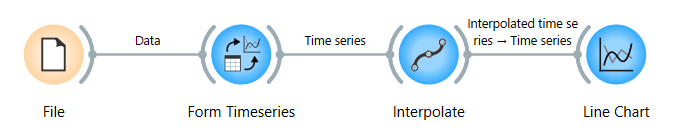
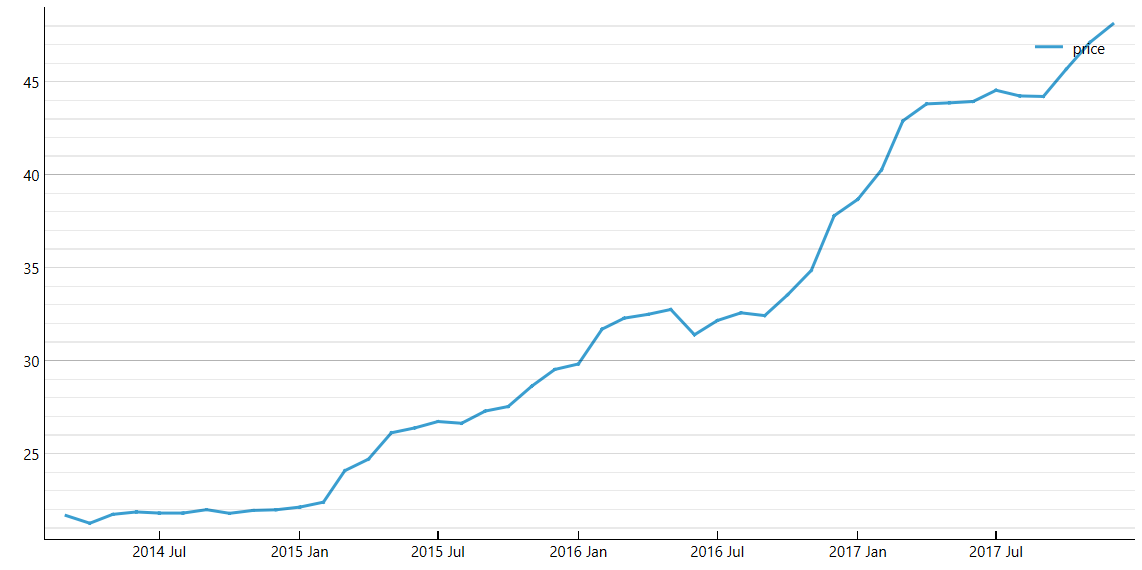
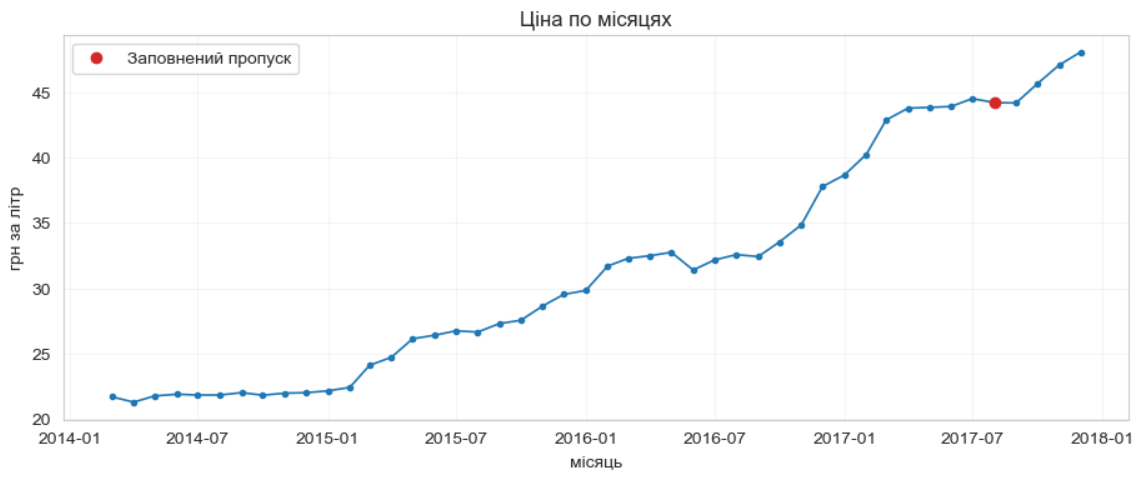

**Висновок до завдання 11:**

Можемо бачити, що форма кривої з Orange відтворює форму нашої кривої, що логічно, адже вони були побудовані на однакових даних

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково - якщо картина різна, перевірте, чи однакові дані на вході.

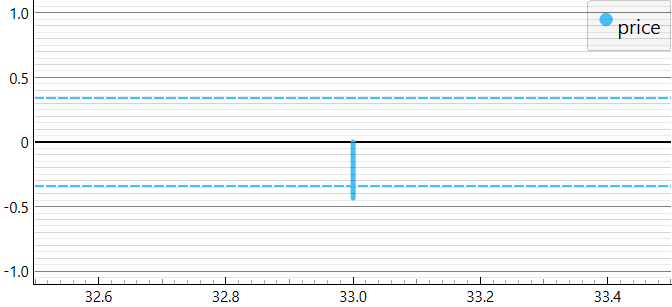
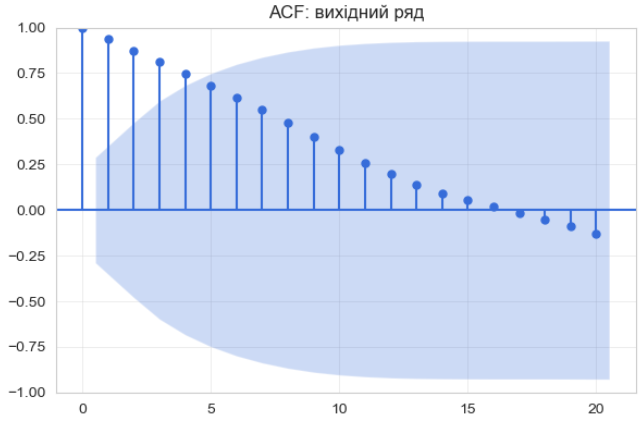


In [32]:
from statsmodels.tsa.stattools import acf

ORANGE_LAG = 33
ORANGE_VALUE = -0.43

acf_values = acf(SERIES, nlags=ORANGE_LAG)

print(f'ACF на лагу {ORANGE_LAG} у Python: {acf_values[ORANGE_LAG]:.3f}')
print(f'ACF на лагу {ORANGE_LAG} в Orange: {ORANGE_VALUE:.2f}')

ACF на лагу 33 у Python: -0.434
ACF на лагу 33 в Orange: -0.43


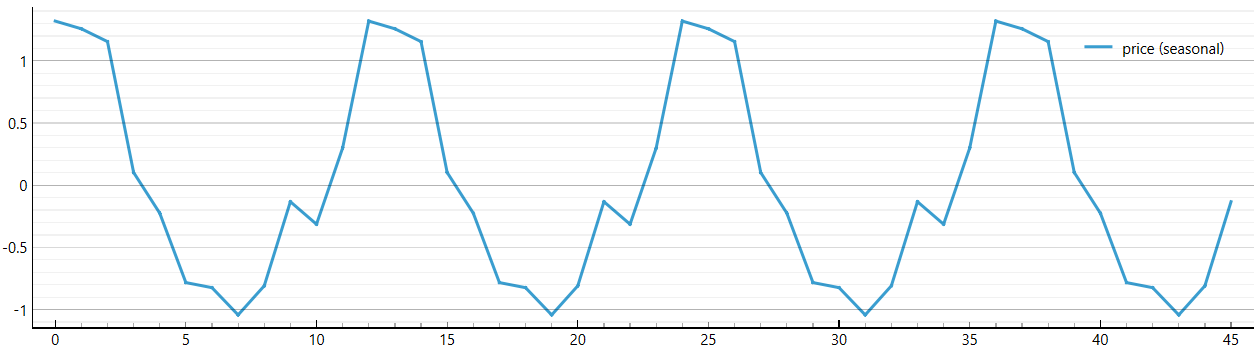
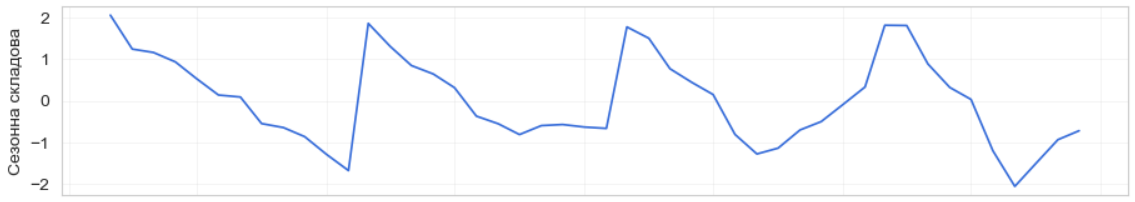

**Висновок до завдання 12:**

У віджеті Correlogram (Orange) відобразився лише один стовпчик, на лагу 33 (≈ −0.43). Це значення збігається з ACF у Python (−0.434), тож дані на вході однакові й обчислення збігаються. Решту лагів віджет не намалював, тому порівняти набір значущих лагів зі знімком Orange неможливо

Сезонна складова Orange є строго періодичною: однакова форма кожного року, розмах від ≈ −1.0 до ≈ +1.3 грн, максимум у березні–квітні, мінімум восени. Сезонна складова STL має схожу фазу (максимум навесні кожного року), але її форма й амплітуда змінюються від року до року (максимуми ≈ 1.8–2.0 грн, мінімуми до ≈ −2.0 грн, розмах приблизно удвічі більший). Причина в різних методах: Orange рахує один сталий сезонний профіль для всіх років, а STL (LOESS) дозволяє сезонності повільно змінюватися. Для ряду зі швидким трендом сталий профіль залишає частину тренду в сезонній складовій, тому оцінки різняться за величиною.

Сезонна складова в обох випадках мала порівняно з трендом (ряд зростає з ≈ 22 до ≈ 48 грн), тож скоригований ряд лише трохи відрізняється від вихідного. Чи є сезонність значущою, визначає сила сезонності F_S = [значення із завдання 4] відносно порогу 0.64, а не сам вигляд складової

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) - наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange - тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду - порахуйте, якої саме.

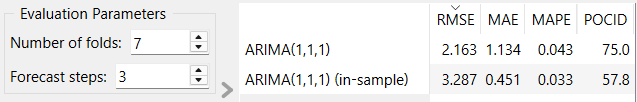
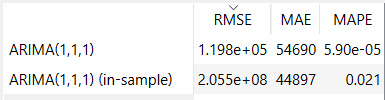
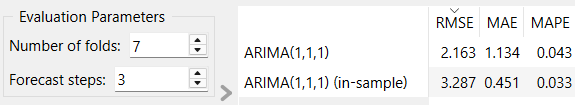
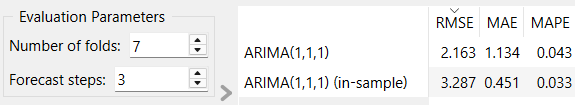
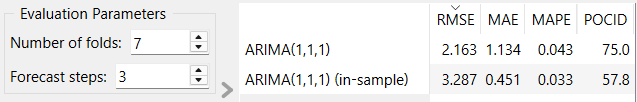

**Висновок до завдання 13:**
Якщо обрати 20 фолдів ми отримаємо:
`Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.`
Причина в довжині ряду. Для 20 фолдів по 3 кроки потрібно 20 × 3 = 60 місяців лише для тестових вікон, а в ряді всього 46 спостережень, тому навіть без навчальної частини вікна не вміщаються. Повідомлення походить із самого віджета, який перевіряє, чи вистачає даних для заданої кількості фолдів і кроку, і зупиняється ще до навчання моделі. При 7 фолдах тестова частина становить 7 × 3 = 21 місяць, і на навчання першого фолда лишається 46 − 21 = 25 місяців.

При такій схемі модель навчається на відрізках від березня 2014 до березня 2016 (фолд 1, тест квітень–червень 2016), до червня 2016 (фолд 2), вересня 2016 (3), грудня 2016 (4), березня 2017 (5), червня 2017 (6) і вересня 2017 (фолд 7, тест жовтень–грудень 2017). Навчальна частина кожного наступного фолда на 3 місяці довша за попередню (25, 28, 31, 34, 37, 40, 43 місяці).

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange - `RMSE`, `MAE`, `MAPE`, `POCID` - **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** - і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті - шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [33]:
N_FOLDS = 7
STEPS = 3
ORANGE_REFERENCE = {'RMSE': 2.163, 'MAE': 1.134, 'MAPE': 0.043, 'POCID': 75.0}


def orange_rmse(true, pred):
    return np.sqrt(np.sum((true - pred) ** 2) / len(pred))


def orange_mae(true, pred):
    return np.median(np.abs(true - pred))


def orange_mape(true, pred):
    return np.mean(np.abs(true - pred)) / np.abs(true).mean()


def orange_pocid(true, pred):
    return 100 * np.mean(np.diff(true) * np.diff(pred) > 0)


orange_true, orange_pred = [], []
for fold in range(1, N_FOLDS + 1):
    train_end = -fold * STEPS
    orange_true.extend(values[train_end:][:STEPS])
    orange_pred.extend(arima_forecaster(values[:train_end], STEPS))

orange_true = np.array(orange_true)
orange_pred = np.array(orange_pred)

reproduction = pd.DataFrame({
    'Orange': ORANGE_REFERENCE,
    'Python (формула Orange)': {
        'RMSE': orange_rmse(orange_true, orange_pred),
        'MAE': orange_mae(orange_true, orange_pred),
        'MAPE': orange_mape(orange_true, orange_pred),
        'POCID': orange_pocid(orange_true, orange_pred),
    },
})
reproduction['різниця'] = reproduction['Python (формула Orange)'] - reproduction['Orange']
print(reproduction.round(3))

       Orange  Python (формула Orange)  різниця
RMSE    2.163                    2.163      0.0
MAE     1.134                    1.134      0.0
MAPE    0.043                    0.043      0.0
POCID  75.000                   75.000      0.0


D:\Programs\Anaconda3\envs\workspace\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [34]:
absolute_error = np.abs(orange_true - orange_pred)
pair_index = np.arange(len(orange_true) - 1)
crosses_fold = (pair_index + 1) % STEPS == 0
direction_hit = np.diff(orange_true) * np.diff(orange_pred) > 0

standard_definitions = pd.Series({
    'MAE (середнє)': absolute_error.mean(),
    'MAE (медіана, як в Orange)': np.median(absolute_error),
    'MAPE, % (середнє відношень)': np.mean(absolute_error / orange_true) * 100,
    'MAPE (частка, як в Orange)': absolute_error.mean() / orange_true.mean(),
    'POCID, % (усі пари, як в Orange)': 100 * direction_hit.mean()
})

print('Пар на межі фолдів:', int(crosses_fold.sum()), 'з', len(pair_index))
print(standard_definitions.round(3))

Пар на межі фолдів: 6 з 20
MAE (середнє)                        1.709
MAE (медіана, як в Orange)           1.134
MAPE, % (середнє відношень)          4.401
MAPE (частка, як в Orange)           0.043
POCID, % (усі пари, як в Orange)    75.000
dtype: float64


**Висновок до завдання 14:**

Метрики Orange відтворено в Python за формулами з вихідного коду додатка на тій самій моделі ARIMA(1,1,1) і тих самих 7 фолдах по 3 кроки. Метрики рахуються один раз по об'єднаних прогнозах усіх фолдів, а не усереднюються по фолдах.

| Метрика | Значення Orange | Відтворення в Python | Формула |
|---|---|---|---|
| RMSE | 2.163 | 2.163 | √(Σ(y − ŷ)² / n) |
| MAE | 1.134 | 1.134 | медіана \|y − ŷ\| |
| MAPE | 0.043 | 0.043 | mean\|y − ŷ\| / mean\|y\| (частка) |
| POCID | 75.000 | 75.000 | 100 · mean(Δy · Δŷ > 0) |

Усі чотири значення збігаються з таблицею Orange до третього знака, тож дані, модель і фолди в обох середовищах однакові, а різниця з звичними числами зумовлена лише означеннями метрик.

Для порівняння, ті самі прогнози за звичними означеннями:

| Метрика | Orange | Звичне означення |
|---|---|---|
| MAE | 1.134 (медіана) | 1.709 (середнє) |
| MAPE | 0.043 (частка) | 4.401 % (середнє відношень) |
| POCID | 75.0 % (усі 20 пар) | 65.0 % (хронологічний порядок), 71.4 % (без пар на межі фолдів) |

**Метрика, що не відповідає назві.** Найяскравіше це MAE: в Orange вона є медіаною абсолютних помилок (у коді підпис «Median absolute error»), а не їхнім середнім, як зазвичай позначає ця абревіатура. Через це Orange показує 1.134 замість середнього 1.709, бо кілька великих помилок підтягують середнє, але майже не впливають на медіану. MAPE теж відхиляється від звичного означення: це середня абсолютна помилка, поділена на середнє фактичних значень, подана як частка, а не середнє відносних помилок у відсотках. У POCID різниці береться по об'єднаному масиву фолдів, тому 6 з 20 пар лежать на межі фолдів і порівнюють не сусідні місяці. Це завищує результат: 75 % в Orange проти 65 % у хронологічному порядку.

**Збіглася одразу** RMSE: це стандартна формула кореня із середнього квадрата помилки, яка не залежить від порядку фолдів чи способу усереднення.

**Висновок.** Перш ніж порівнювати числа з двох різних інструментів, треба перевірити: що саме означає однакова абревіатура (середнє чи медіана, частка чи відсотки, на яке значення ділиться помилка), як об'єднуються фолди (по об'єднаних прогнозах чи по середньому метрик) і в якому порядку, а також чи однакові дані та модель на вході. Розбіжність не є помилкою жодного з інструментів, але без відтворення формул твердження «метрики різні, бо середовища різні» нічого не пояснює.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки - що сталося насправді (зросла / впала),
стовпці - що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця - часоворядовий відповідник матриці похибок із класифікації.

In [35]:
ORANGE_POCID = 75.0
LABELS = ['зросла', 'впала']


def direction_matrix(true, pred):
    actual_change = np.diff(true)
    predicted_change = np.diff(pred)
    assert (actual_change != 0).all() and (predicted_change != 0).all()
    matrix = pd.crosstab(
        pd.Categorical(np.where(actual_change > 0, LABELS[0], LABELS[1]), categories=LABELS),
        pd.Categorical(np.where(predicted_change > 0, LABELS[0], LABELS[1]), categories=LABELS),
        rownames=['факт'],
        colnames=['прогноз'],
    )
    return matrix


matrix_orange = direction_matrix(orange_true, orange_pred)
accuracy_orange = 100 * np.trace(matrix_orange.to_numpy()) / matrix_orange.to_numpy().sum()

print(matrix_orange)
print(f'Частка правильних: {accuracy_orange:.1f} %; POCID Orange: {ORANGE_POCID:.1f} %')

прогноз  зросла  впала
факт                  
зросла       10      1
впала         4      5
Частка правильних: 75.0 %; POCID Orange: 75.0 %


**Висновок до завдання 15:**

Матриця напрямку зміни (рядки: факт, стовпці: прогноз; 20 пар сусідніх значень в об'єднаному масиві фолдів, як рахує Orange):

| | прогноз: зросла | прогноз: впала |
|---|---|---|
| **факт: зросла** | 10 | 1 |
| **факт: впала** | 4 | 5 |

Частка правильних відповідей (діагональ) = (10 + 5) / 20 = 75 %, що збігається зі значенням POCID в Orange. У хронологічному порядку, де всі пари є справді сусідніми місяцями, частка становить 65 %.

Модель частково корисна для рішення «купувати зараз чи чекати». Зростання вона розпізнає майже завжди (10 із 11, тобто 91 %), але падіння вгадує лише в 5 випадках із 9 (56 %): чотири рази передбачила зростання, коли ціна впала. Отже, її прогноз «зросте» правильний у 10 випадках із 14 (71 %), а прогноз «впаде» у 5 із 6 (83 %), але таких прогнозів мало. Базою для порівняння є не 50 %, а наївна відповідь «завжди зросте»: ціна зросла в 11 парах із 20, тож така відповідь дала б 55 %. Модель перевершує цю базу на 20 процентних пунктів (75 % проти 55 %), але в хронологічному порядку перевага зменшується до 10 пунктів (65 % проти 55 %), і на вибірці з 20 пар це легко може бути випадковістю.

Це інше питання, ніж у MAE та RMSE: вони вимірюють, наскільки далеко прогноз від фактичного значення, і не враховують знак зміни. Модель може мати малу середню помилку, але хибно вказувати напрямок, і навпаки: вгадувати напрямок, але помилятися на кілька гривень у величині. Для вибору між «купити зараз» і «зачекати» важливий знак зміни, а для оцінки бюджету важлива її величина.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так - чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

**Загальний висновок**

1. **Сезонність.** Сезонність у ряді сметани (Херсон) слабка: сила сезонності F_S = 0.549 не перевищує поріг 0.64, а ряд визначається насамперед зростаючим трендом (з ≈ 22 до ≈ 48 грн за літр). Сезонні складові STL і Orange мають схожу фазу (максимум навесні), але різну амплітуду, тому висновок про сезонність залежить від методу.

2. **Найкращий метод.** Найкращим базисом на ретроспективній перевірці (7 фолдів × 3 кроки) став дрейф (MAE 1.17, RMSE 1.63), що природно для ряду зі сталим зростанням. ARIMA(1,1,1) (MAE 1.71, RMSE 2.16) приблизно дорівнює наївному прогнозу і програє дрейфу, тому для цього ряду вона не виправдовує свою складність.

3. **Точка зміни режиму.** Точку зміни рівня знайдено в березні 2017 (t = 16.07, середнє зросло з 27.9 до 44.9 грн), і вона значуща навіть із поправкою Бонферроні. Проте тест рівня на ряді з трендом завищує значущість, а зовнішнє пояснення (наприклад, подорожчання молочної сировини) із даних не випливає і потребує окремого підтвердження.

4. **Різниця метрик.** Однаково названі метрики дали різні числа, бо Orange вживає інші означення: MAE є медіаною помилок (1.134 проти середнього 1.709), MAPE подано як частку (0.043 проти 4.4 %), а POCID рахується по об'єднаних фолдах (75 % проти 65 % у хронологічному порядку). Після відтворення формул у Python значення збіглися з Orange до третього знака, тож розбіжність зумовлена лише означеннями.

5. **Обмеження довжини ряду.** Через 46 спостережень не вдалося надійно встановити, чи є сезонність стійкою (лише 3–4 повні цикли), перевірити модель на довших горизонтах (20 фолдів по 3 кроки не вміщаються) і довести, що перевага одного методу над іншим не випадкова.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь                                                                                                                                                 |
|---|----------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Які інструменти використано (назва, версія) | Claude Sonnet 5.5                                                                                                                                              |
| Для яких саме завдань | Генерація коду та пояснення термінів і понять                                                                                                                  |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код                                                                                                                                                            |
| Що ви змінили у згенерованому результаті й чому | Змінив підписи, додав власні елементи при аналізі даних                                                                                                        |
| Що з отриманого ви **перевірили самостійно** і яким способом | Перевірив отримані метрики шляхом проведення аналогічних операцій у Orange, також перевіряв пропушений місяць та крайні межі ведення обліку кожного з регіонів |
| Чи траплялися у відповідях ШІ помилки; якщо так - які | Не траплялися                                                                                                                                                  |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________